In [1]:
import sys
sys.path.append('..')
from pymeasure.log import console_log
from pymeasure.experiment import Results, unique_filename
from datetime import date

from pymeasure.experiment import Procedure
from pymeasure.experiment import IntegerParameter, FloatParameter, BooleanParameter, Parameter
from pymeasure.adapters import DAQmxAdapter
from instruments.sr830 import SR830
from pymeasure.instruments.keithley import Keithley2400, Keithley2000, Keithley6221
from instruments.dsp7265 import DSP7265
from time import sleep, time
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

SENSITIVITIES = [
        2e-9, 5e-9, 10e-9, 20e-9, 50e-9, 100e-9, 200e-9,
        500e-9, 1e-6, 2e-6, 5e-6, 10e-6, 20e-6, 50e-6, 100e-6,
        200e-6, 500e-6, 1e-3, 2e-3, 5e-3, 10e-3, 20e-3,
        50e-3, 100e-3, 200e-3, 500e-3, 1]
TIME_CONSTANTS = [
        10e-6, 30e-6, 100e-6, 300e-6, 1e-3, 3e-3, 10e-3,
        30e-3, 100e-3, 300e-3, 1, 3, 10, 30, 100, 300, 1e3,
        3e3, 10e3, 30e3]

dsp_SENSITIVITIES = [
        np.nan, 2.0e-9, 5.0e-9, 10.0e-9, 20.0e-9, 50.0e-9, 100.0e-9,
        200.0e-9, 500.0e-9, 1.0e-6, 2.0e-6, 5.0e-6, 10.0e-6,
        20.0e-6, 50.0e-6, 100.0e-6, 200.0e-6, 500.0e-6, 1.0e-3,
        2.0e-3, 5.0e-3, 10.0e-3, 20.0e-3, 50.0e-3, 100.0e-3,
        200.0e-3, 500.0e-3, 1.0]

dsp_TIME_CONSTANTS = [
        10.0e-6, 20.0e-6, 40.0e-6, 80.0e-6, 160.0e-6, 320.0e-6,
        640.0e-6, 5.0e-3, 10.0e-3, 20.0e-3, 50.0e-3, 100.0e-3,
        200.0e-3, 500.0e-3, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0,
        100.0, 200.0, 500.0, 1.0e3, 2.0e3, 5.0e3, 10.0e3,
        20.0e3, 50.0e3]

In [9]:
#========FUNCTIONS FOR SRS-current DSP-voltage========#

#==============INITIALIZING INSTRUMENTS==============#
#SRS Lock-In to Mesasure Current
lockin = SR830("GPIB::9")
lockin.input_config = 'I (1 MOhm)'
lockin.harmonic = 1
lockin.time_constant = 1
lockin.sensitivity = 1
lockin.frequency = 17

#DSP Lock-In to Measure Voltage
dsp = DSP7265("GPIB::12")
dsp.imode = 'voltage mode'
dsp.harmonic = 1
dsp.setDifferentialMode()
dsp.sensitivity = 5e-3
dsp.time_constant = 1
dsp.reference = 'external front'
dsp.auto_phase()

dsp2 = DSP7265("GPIB::11")
dsp2.imode = 'voltage mode'
dsp2.harmonic = 1
dsp2.setDifferentialMode()
dsp2.sensitivity = 5e-3
dsp2.time_constant = 1
dsp2.reference = 'external front'
dsp2.auto_phase()

dsp3 = DSP7265("GPIB::10")
dsp3.imode = 'voltage mode'
dsp3.harmonic = 1
dsp3.setDifferentialMode()
dsp3.sensitivity = 5e-3
dsp3.time_constant = 1
dsp3.reference = 'external front'
dsp3.auto_phase()

#Keithley Top Gate
top_gate = Keithley2400("GPIB::04")
top_value = 0
current_top = top_gate.source_voltage
top_gate.ramp_to_voltage(top_value, steps = abs(int(40*(top_value - current_top))), pause = 0.1)

#Keithley Bottom Gate
# bottom_gate = Keithley2400("GPIB::04")
# bottom_value = 0
# current_bottom = bottom_gate.source_voltage
# bottom_gate.ramp_to_voltage(bottom_value, steps = abs(int(40*(bottom_value - current_bottom))), pause = 0.1)


#==============INITIALIZING FUNCTIONS==============#
#Device Safe Function
def device_safe_DSP(safe_voltage):
    device_voltage = dsp.x
    if device_voltage > safe_voltage:
        print('Safe device voltage exceeded')
        return 0
    else:
        return 1

#Shutdown Function
def source_shutdown_DSP(shutdown_step):
    """
    Shut down source without burning device.
    """
    print('Source shutdown started!')
    while lockin.sine_voltage > 0.005:
        sleep(0.2)
        lockin.sine_voltage = lockin.sine_voltage - shutdown_step
        sleep(0.2)
        
    print('Source shutdown properly!')
    print('Sine voltage at',lockin.sine_voltage,'V')
    print('Device voltage at',dsp.x,'V')

#Ramp to Voltage Target Function
def ramp_voltage_target_DSP(target,ramp_step,safe_voltage): # Target voltage function definition
    """
    target = target of device voltage
    ramp_step = ramping steps for sine voltage
    """
    print('Starting ramping device voltage with target',target,'V')
    device_voltage = dsp.x
    while abs(device_voltage - target) > 0.0003:
        lockin.sine_voltage = lockin.sine_voltage + ramp_step

        sleep(4)
        device_voltage = dsp.x
        print('Current device voltage',dsp.x,'V')
        
        safe = device_safe_DSP(safe_voltage)
        if safe == 0:
            source_shutdown_DSP(0.002)
            return 0
            break

        sleep(0.5)
        device_voltage = dsp.x
        
    print('Device voltage at',device_voltage,'V')
    return 1

#Create Data Table Function
def create_data_table():
    data_table = pd.DataFrame({'Sine Voltage':[],
        'Device Current X':[],
        'Device Current Y':[],
        'Device Voltage X':[],
        'Device Voltage Y':[],
        'Hall Voltage X':[],
        'Hall Voltage Y':[],
        '4pt Voltage X':[],
        '4pt Voltage Y':[],
        'Device Resistance X':[],
        'Hall Resistance X':[],
        '4pt Resistance X':[],
        'Top Gate Voltage':[],
        'Top Leakage Current':[],
        'Bottom Gate Votlage':[],
        'Bottom Leakage Current':[],
        'Current Sensitivty':[],
        'Voltage Sensitivity':[],
        'Elapsed Time':[]
       })
    
    return data_table

#Record Data Table Function
def record_data_DSP(name):
    s_v = lockin.sine_voltage
    i_x = lockin.x
    i_y = lockin.y
    v_x = dsp.x
    v_y = dsp.y
    v2_x = dsp2.x
    v2_y = dsp2.y
    v3_x = dsp3.x
    v3_y = dsp3.y
#     v2_x = 0
#     v2_y = 0
#     v3_x = 0
#     v3_y = 0
    r_x = v_x / i_x
    r2_x = v2_x / i_x
    r3_x = v3_x / i_x
#     r2_x = 0
#     r3_x = 0
    print('Resistance',r_x*1e-3,'kOhms')
    print('Resistance Hall',r2_x*1e-3,'kOhms')
    print('Resistance 4pt',r3_x*1e-3,'kOhms')
    t_v = top_gate.source_voltage
    t_i = top_gate.current[1]
#     b_v = bottom_gate.source_voltage
    b_v = 0
#     b_i = bottom_gate.current[1]
    b_i = 0
    i_sens = lockin.sensitivity
    v_sens = dsp.sensitivity
    t_e = time()
    data_table.loc[len(data_table)] = [s_v,i_x,i_y,v_x,v_y,v2_x,v2_y,v3_x,v3_y,r_x,r2_x,r3_x,t_v,t_i,b_v,b_i,i_sens*1e-6,v_sens,t_e]
    data_table.to_csv(name)

    return data_table

#Create Sweep Points for Gate Function
def gate_sweep_points(start,stop,step):
    points = []
    if start < stop:
        points = np.arange(start, stop, step)# All the current points
        points = np.append(points, stop)
    else: 
        points = np.arange(stop, start, step)# All the current points
        points = np.append(points, start)
        points = np.flip(points)
        
    return points

0.005
0.005
0.005


In [16]:
#========FUNCTIONS FOR SRS-current SRS-voltage========#

#==============INITIALIZING INSTRUMENTS==============#
#SRS Lock-In to Mesasure Current
lockin = SR830("GPIB::7")
lockin.input_config = 'I (1 MOhm)'
lockin.harmonic = 1
lockin.time_constant = 1
lockin.sensitivity = 1
lockin.frequency = 17

#SRS Lock-In to Measure Voltage
# lockinV = SR830("GPIB::8")
# lockinV.input_config = 'A-B'
# lockinV.harmonic = 1
# lockinV.time_constant = 0.1
# lockinV.sensitivity = 20e-3
# lockinV.auto_phase()

#Keithley Top Gate
top_gate = Keithley2400("GPIB::04")
top_value = 0
current_top = top_gate.source_voltage
top_gate.ramp_to_voltage(top_value, steps = abs(int(40*(top_value - current_top))), pause = 0.1)

#Keithley Bottom Gate
# bottom_gate = Keithley2400("GPIB::04")
# bottom_value = 0
# current_bottom = bottom_gate.source_voltage
# bottom_gate.ramp_to_voltage(bottom_value, steps = abs(int(40*(bottom_value - current_bottom))), pause = 0.1)


#==============INITIALIZING FUNCTIONS==============#
#Device Safe Function
def device_safe_SRS(safe_voltage):
    device_voltage = srs.x
    if device_voltage > safe_voltage:
        print('Safe device voltage exceeded')
        return 0
    else:
        return 1

#Shutdown Function
def source_shutdown_SRS(shutdown_step): # Shutdown function definition
    """
    Shut down source without burning device.
    """
    print('Source shutdown started!')
    while lockin.sine_voltage > 0.005:
        sleep(1)
        lockin.sine_voltage = lockin.sine_voltage - shutdown_step
        sleep(1)
        
    print('Source shutdown properly!')
    print('Sine voltage at',lockin.sine_voltage,'V')
    print('Device voltage at',lockinV.x,'V')
    
#Ramp to Voltage Target Function
def ramp_voltage_target_SRS(target,ramp_step,safe_voltage): # Target voltage function definition
    """
    target = target of device voltage
    ramp_step = ramping steps for sine voltage
    """
    print('Starting ramping device voltage with target',target,'V')
    check = lockinV.x
    while abs(check - target) > 0.0003:
        sleep(1)
        lockin.quick_range()
        if lockin.sensitivity == 1:
            print('Current sensitivity exceeded')
            source_shutdown(0.002)
            break
        lockinV.quick_range()
        if lockinV.sensitivity == 1:
            print('Voltage sensitivity exceeded')
            source_shutdown(0.002)
            break
        lockin.sine_voltage = lockin.sine_voltage + ramp_step
        print('Current device voltage',lockinV.x,'V')
        if lockinV.x > safe_voltage:
            print('Safe device voltage exceeded')
            source_shutdown(0.002)
            break
        check = lockinV.x
        sleep(1)
    print('Device voltage at',lockinV.x,'V')

#Create Data Table Function
def create_data_table():
    data_table = pd.DataFrame({'Sine Voltage':[],
        'Device Current X':[],
        'Device Current Y':[],
        'Device Voltage X':[],
        'Device Voltage Y':[],
        'Device Resistance X':[],
        'Top Gate Voltage':[],
        'Top Leakage Current':[],
        'Bottom Gate Votlage':[],
        'Bottom Leakage Current':[],
        'Current Sensitivty':[],
        'Voltage Sensitivity':[],
        'Elapsed Time':[]
       })
    
    return data_table

#Record Data Table Function
def record_data_SRS(name):
    s_v = lockin.sine_voltage
    i_x = lockin.x
    i_y = lockin.y
    v_x = lockinV.x
    v_y = lockinV.y
    r_x = v_x / i_x
    t_v = top_gate.source_voltage
    t_i = top_gate.current[1]
    b_v = bottom_gate.source_voltage
    b_i = bottom_gate.current[1]
    i_sens = lockin.sensitivity
    v_sens = lockinV.sensitivity
    t_e = time()
    data_table.loc[len(data_table)] = [s_v,i_x,i_y,v_x,v_y,r_x,t_v,t_i,b_v,b_i,i_sens*1e-6,v_sens,t_e]
    data_table.to_csv(name)
    
    return data_table

#Create Sweep Points for Gate Function
def gate_sweep_points(start,stop,step):
    points = []
    if start < stop:
        points = np.arange(start, stop, step)# All the current points
        points = np.append(points, stop)
    else: 
        points = np.arange(stop, start, step)# All the current points
        points = np.append(points, start)
        points = np.flip(points)
        
    return points

VisaIOError: VI_ERROR_NLISTENERS (-1073807265): No listeners condition is detected (both NRFD and NDAC are deasserted).

In [24]:
lockin.sine_voltage = 0.004
safe = ramp_voltage_target_DSP(0.005,0.002,0.008)
print(safe)
#source_shutdown_DSP(0.002)

Starting ramping device voltage with target 0.005 V
Current device voltage 0.0009865 V
Current device voltage 0.001313 V
Current device voltage 0.001642 V
Current device voltage 0.00197 V
Current device voltage 0.002299 V
Current device voltage 0.0026285 V
Current device voltage 0.002958 V
Current device voltage 0.003286 V
Current device voltage 0.003615 V
Current device voltage 0.003941 V
Current device voltage 0.00427 V
Current device voltage 0.004598 V
Current device voltage 0.004927 V
Device voltage at 0.004927 V
1


In [5]:
source_shutdown_DSP(0.004)

Source shutdown started!
Source shutdown properly!
Sine voltage at 0.004 V
Device voltage at 0.001333 V


In [82]:
lockin.sine_voltage = 0.004
lockin.quick_range()
sleep(0.5)
print('Applied voltage:',lockin.sine_voltage,'V')
print('Device voltage:',dsp.x,'V')
print('Measured current:',lockin.x,'A')
resistance =  dsp.x / lockin.x
print('Measured resistace:',resistance,'Ohms')

Applied voltage: 0.004 V
Device voltage: 0.0006055 V
Measured current: 2.47648e-12 A
Measured resistace: 243322201.9956037 Ohms


In [6]:
start_top_gate = 0
top_start = top_gate.source_voltage
top_gate.ramp_to_voltage(start_top_gate, steps = abs(int(50*(start_top_gate-top_start))), pause = 0.1)

In [89]:
bottom_gate.ramp_to_voltage(0, steps = abs(int(100*(constant_bottom_gate))), pause = 0.1)

In [10]:
#Run Parameters

#Device Measurement Voltage in V
voltage_setpoint = 0.005
#Safe Device Voltage in V
safe_device_voltage = 0.008
#Safe Leakage Current in nA
safe_leak = 2
#Initial Top Voltage Ramp
top_initial_ramp = -7
#Top Voltage Ramp Step
top_ramp_step = 0.1
#Final Top Voltage Ramp
top_final_ramp = -16

print('Running up gate voltage')
top_source_voltage = top_gate.source_voltage
top_gate.ramp_to_voltage(top_initial_ramp, steps = abs(int(50*(top_initial_ramp-top_source_voltage))), pause = 0.1)
top_gate.compliance_current = safe_leak*1e-9

data_table = create_data_table()
safe = ramp_voltage_target_DSP(voltage_setpoint,0.002,safe_device_voltage)

#bottom_start = bottom_gate.source_voltage 
#constant_bottom_gate = -2
#bottom_gate.ramp_to_voltage(constant_bottom_gate, steps = abs(int(100*(constant_bottom_gate))), pause = 0.1)
 

top_source_voltage = top_gate.source_voltage
top_voltage_points = gate_sweep_points(top_source_voltage,top_final_ramp,top_ramp_step)

for top_voltage in top_voltage_points:    
    if safe == 0:
        break
    top_source_voltage = top_gate.source_voltage
    top_gate.ramp_to_voltage(top_voltage, steps = abs(int(40*(top_voltage - top_source_voltage))), pause = 0.1)
    print('Top gate voltage',top_gate.source_voltage,'V')
    print('Top gate leakage current',top_gate.current[1]*1e9,'nA')
    #print('Bottom gate leakage current',bottom_gate.current[1]*10e9,'nA')
    leakage = top_gate.current[1]*1e9
    if abs(leakage) > safe_leak:
        break
    
    sleep(4)
    data_table = record_data_DSP('03112022_2pt_4pt_hall_top_gate_m7_m16_17Hz_leads5_11.csv')
    safe = device_safe_DSP(safe_device_voltage)
    

source_shutdown_DSP(0.004)
    
print('Running down gate voltage')
top_source_voltage = top_gate.source_voltage
top_gate.ramp_to_voltage(0, steps = abs(int(40*(0 - top_source_voltage))), pause = 0.1)
#bottom_gate.ramp_to_voltage(0, steps = abs(int(40*(constant_bottom_gate))), pause = 0.1)

print('Yeet!')

Running up gate voltage
Starting ramping device voltage with target 0.005 V
Current device voltage 0.0003745 V
Current device voltage 0.0004985 V
Current device voltage 0.0006235 V
Current device voltage 0.0007485 V
Current device voltage 0.0008735 V
Current device voltage 0.0009985 V
Current device voltage 0.001124 V
Current device voltage 0.001251 V
Current device voltage 0.0013985 V
Current device voltage 0.0015245 V
Current device voltage 0.0016525 V
Current device voltage 0.001779 V
Current device voltage 0.0019065 V
Current device voltage 0.002034 V
Current device voltage 0.0021605 V
Current device voltage 0.002288 V
Current device voltage 0.002415 V
Current device voltage 0.0025415 V
Current device voltage 0.002669 V
Current device voltage 0.0027955 V
Current device voltage 0.002923 V
Current device voltage 0.0030505 V
Current device voltage 0.0031775 V
Current device voltage 0.003305 V
Current device voltage 0.0034325 V
Current device voltage 0.0035585 V
Current device voltage 

Resistance -113404.7229050522 kOhms
Resistance Hall -2629.464964188617 kOhms
Resistance 4pt -2525.7337775279652 kOhms
Top gate voltage -10.8 V
Top gate leakage current -0.009480319000000001 nA
Resistance -93167.33257229833 kOhms
Resistance Hall -2457.508878741756 kOhms
Resistance 4pt -2250.9988584474886 kOhms
Top gate voltage -10.9 V
Top gate leakage current -0.009529606 nA
Resistance -80648.75844487372 kOhms
Resistance Hall -1664.0990361950119 kOhms
Resistance 4pt -2252.881293125041 kOhms
Top gate voltage -11.0 V
Top gate leakage current -0.02127178 nA
Resistance -71679.47846185276 kOhms
Resistance Hall -2088.7139315694626 kOhms
Resistance 4pt -1444.7192128140312 kOhms
Top gate voltage -11.1 V
Top gate leakage current -0.004201292 nA
Resistance -103432.11566091163 kOhms
Resistance Hall -4092.400236743153 kOhms
Resistance 4pt -3205.7135187821364 kOhms
Top gate voltage -11.2 V
Top gate leakage current -0.01693016 nA
Resistance -169468.3071554487 kOhms
Resistance Hall -17303.71993929278 

Top gate voltage -15.2 V
Top gate leakage current -0.03395127 nA
Resistance 7676.529140761137 kOhms
Resistance Hall 6627.24290037415 kOhms
Resistance 4pt 27.706056137222145 kOhms
Top gate voltage -15.3 V
Top gate leakage current -0.03528342 nA
Resistance 6752.544145448695 kOhms
Resistance Hall 6044.320708855523 kOhms
Resistance 4pt 22.444793049354416 kOhms
Top gate voltage -15.4 V
Top gate leakage current -0.005582684 nA
Resistance 5946.4772767525055 kOhms
Resistance Hall 5256.379764898768 kOhms
Resistance 4pt 0.7995263565381521 kOhms
Top gate voltage -15.5 V
Top gate leakage current -0.022899740000000002 nA
Resistance 5967.07035316221 kOhms
Resistance Hall 4870.896488689162 kOhms
Resistance 4pt 2.6277705842029095 kOhms
Top gate voltage -15.6 V
Top gate leakage current -0.01796608 nA
Resistance 5894.760867466011 kOhms
Resistance Hall 4868.303730986716 kOhms
Resistance 4pt 6.849735955345039 kOhms
Top gate voltage -15.7 V
Top gate leakage current -0.024725280000000002 nA
Resistance 5362.

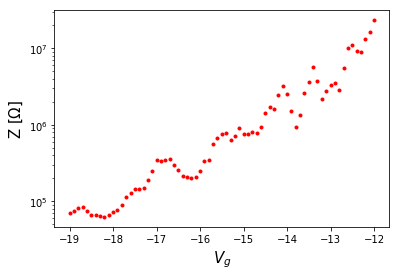

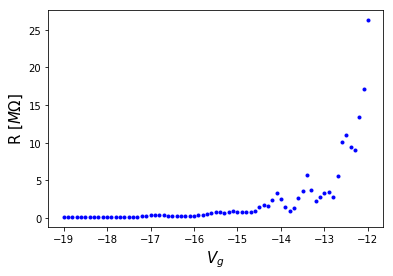

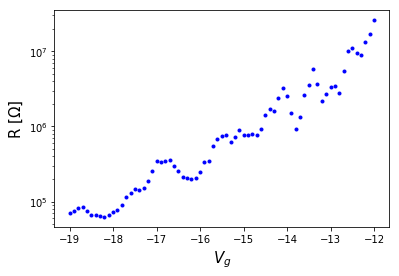

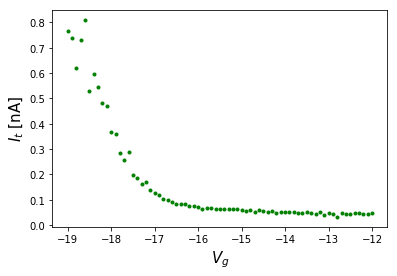

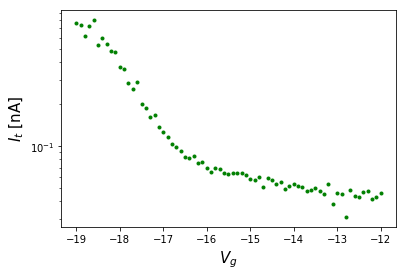

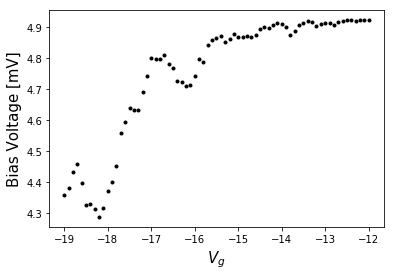

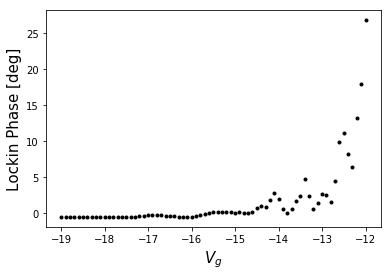

In [56]:
#0 to m12 at 83 Hz
s = data_table['Sine Voltage']
r = data_table["Device Resistance X"]
v = data_table['Device Voltage X']
top = data_table["Top Gate Voltage"]
i = data_table["Device Current X"]
leak = data_table["Top Leakage Current"]
iy = data_table['Device Current Y']







rtot = v / np.sqrt(i**2 + iy**2)
plt.plot(top, rtot,'r.')
plt.xlabel(r'$V_g$', size = 15)
plt.ylabel(r'Z [$\Omega$]', size = 15)
plt.yscale('log')
plt.show()


plt.plot(top, r/1e6, 'b.')
plt.ylabel(r'R [$M\Omega$]', size = 15)
plt.xlabel(r'$V_g$', size = 15)
#plt.yscale('log')
plt.show()




plt.plot(top, r, 'b.')
plt.ylabel(r'R [$\Omega$]', size = 15)
plt.xlabel(r'$V_g$', size = 15)
plt.yscale('log')
plt.show()



#plt.plot(top, i,'b*')
#plt.show()
#plt.plot(top, r, 'k.')
#plt.show()

plt.plot(top, -1*leak*1e9, 'g.')
#plt.yscale('log')
plt.xlabel(r'$V_g$', size = 15)
plt.ylabel(r'$I_t$ [nA]', size = 15)
plt.show()


plt.plot(top, -1*leak*1e9, 'g.')
plt.yscale('log')
plt.xlabel(r'$V_g$', size = 15)
plt.ylabel(r'$I_t$ [nA]', size = 15)
plt.show()


plt.plot(top, v*1e3, 'k.')

plt.xlabel(r'$V_g$', size = 15)
plt.ylabel(r'Bias Voltage [mV]', size = 15)
plt.show()

plt.plot(top, np.arctan2(iy,i) * 180/ np.pi ,'k.')
plt.xlabel(r'$V_g$', size = 15)
plt.ylabel(r'Lockin Phase [deg]', size = 15)
plt.show()

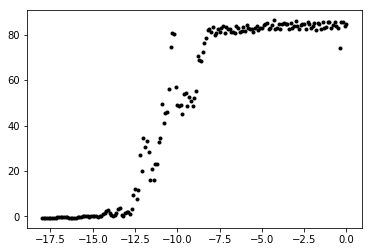

In [32]:
plt.plot(top, np.arctan2(iy,i) * 180/ np.pi ,'k.')

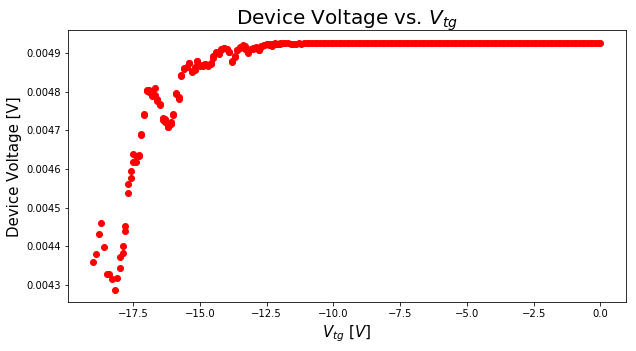

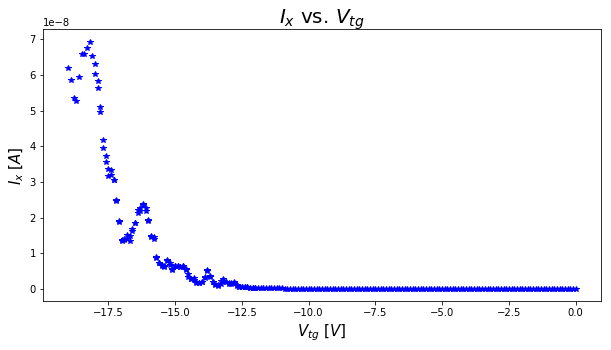

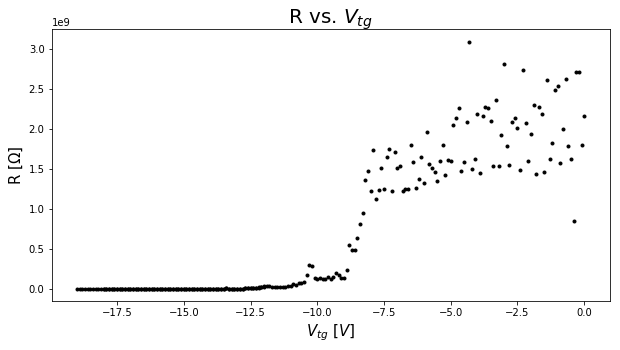

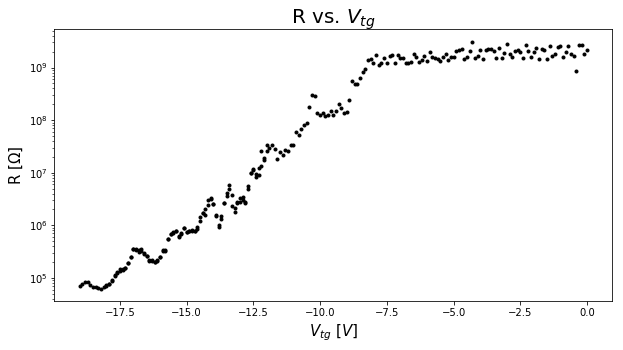

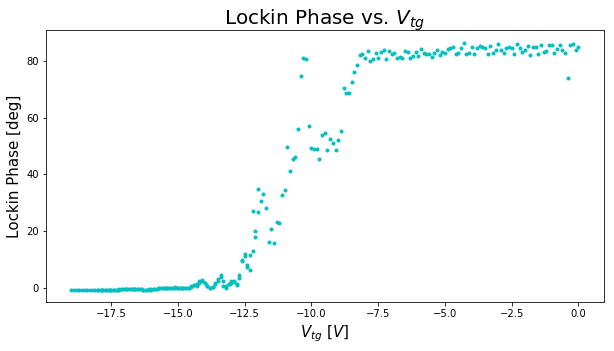

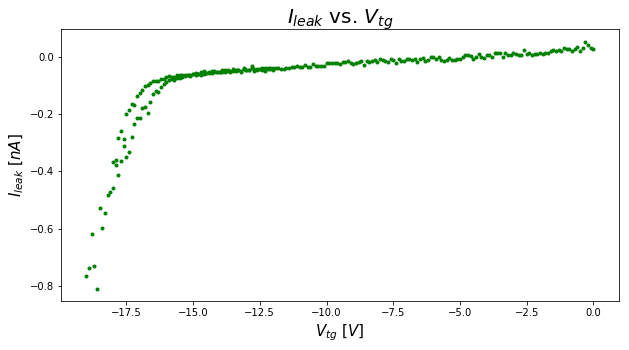

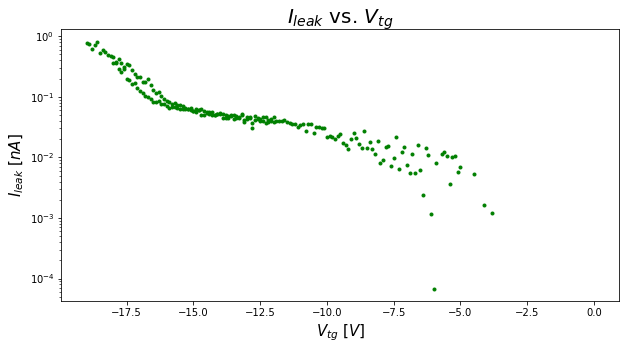

In [69]:
%matplotlib inline

prev1 = pd.read_csv('phase_am_top_gate_m0_m18_17Hz.csv')
prev2 = pd.read_csv('phase_am_top_gate_m12_m19_17Hz.csv')
# prev3 = pd.read_csv('top_gate_m9_m14.csv')
# prev4 = pd.read_csv('top_gate_m10_m15.csv')
# prev5 = pd.read_csv('top_gate_m12_m16.csv')
prev = pd.concat([prev1,prev2])

# prev1 = pd.read_csv('top_gate_0_m12_83Hz.csv')
# prev2 = pd.read_csv('top_gate_m7_m15_83Hz.csv')
# prev = pd.concat([prev1,prev2])

#prev = pd.read_csv('top_gate_m0_m16_147Hz.csv')

plt.rcParams['figure.figsize'] = [10, 5]

s = prev['Sine Voltage']
r = prev["Device Resistance X"]
v = prev['Device Voltage X']
top = prev["Top Gate Voltage"]
i = prev["Device Current X"]
leak = prev["Top Leakage Current"]
iy = prev['Device Current Y']

plt.title(r'Device Voltage vs. $V_{tg}$',size = 20)
plt.xlabel(r"$V_{tg}$ $ [V]$", size = 15)
plt.ylabel(r"Device Voltage [V]", size = 15)
plt.plot(top, v,'ro')
plt.savefig("Device_voltage_m0_m19_phase.png")
plt.show()

# rtot = v / np.sqrt(i**2 + iy**2)
# plt.title(r'Z vs. $V_{tg}$',size = 20)
# plt.xlabel(r"$V_{tg}$ $ [V]$", size = 15)
# plt.ylabel(r"Z $[\Omega]$", size = 15)
# plt.plot(top, rtot,'r*')
# plt.yscale("log")
# plt.savefig("Z_83.png")
# plt.show()

plt.title(r'$I_x$ vs. $V_{tg}$',size = 20)
plt.xlabel(r"$V_{tg}$ $ [V]$", size = 15)
plt.ylabel(r"$I_x$ $[A]$", size = 15)
plt.plot(top, i,'b*')
plt.savefig("Ix_m0_m19_phase.png")
plt.show()

# plt.title(r'$I_y$ vs. $V_{tg}$',size = 20)
# plt.xlabel(r"$V_{tg}$ $ [V]$", size = 15)
# plt.ylabel(r"$I_y$ $[A]$", size = 15)
# plt.plot(top, iy,'b*')
# plt.savefig("Iy_83.png")
# plt.show()

plt.title(r'R vs. $V_{tg}$',size = 20)
plt.xlabel(r"$V_{tg}$ $ [V]$", size = 15)
plt.ylabel(r"R $[\Omega]$", size = 15)
plt.plot(top, r, 'k.')
plt.savefig("R_m0_m19_phase.png")
plt.show()

plt.title(r'R vs. $V_{tg}$',size = 20)
plt.xlabel(r"$V_{tg}$ $ [V]$", size = 15)
plt.ylabel(r"R $[\Omega]$", size = 15)
plt.plot(top, r, 'k.')
plt.yscale("log")
plt.savefig("log_R_m0_m19_phase.png")
plt.show()

plt.title(r'Lockin Phase vs. $V_{tg}$',size = 20)
plt.xlabel(r"$V_{tg}$ $ [V]$", size = 15)
plt.ylabel(r"Lockin Phase [deg]", size = 15)
plt.plot(top, np.arctan2(iy,i) * 180/ np.pi ,'c.')
plt.savefig("lockin_phase_m0_m19_phase.png")
plt.show()

plt.title(r'$I_{leak}$ vs. $V_{tg}$',size = 20)
plt.xlabel(r"$V_{tg}$ $ [V]$", size = 15)
plt.ylabel(r"$I_{leak}$ $ [nA]$", size = 15)
plt.plot(top, leak*1e9, 'g.')
plt.savefig("Ileak_m0_m19_phase.png")
plt.show()

plt.title(r'$I_{leak}$ vs. $V_{tg}$',size = 20)
plt.xlabel(r"$V_{tg}$ $ [V]$", size = 15)
plt.ylabel(r"$I_{leak}$ $ [nA]$", size = 15)
plt.plot(top, -1*leak*1e9, 'g.')
plt.yscale("log")
plt.savefig("log_Ileak_m0_m19_phase.png")
plt.show()

In [14]:

scan = pd.read_csv('03112022_am_top_gate_m15_m16_17Hz_leads5_4.csv')
r = scan["Top Leakage Current"]
print(r)

0    -3.113925e-11
1    -3.079401e-11
2    -3.444486e-11
3    -3.405007e-11
4    -2.926451e-11
5    -2.911641e-11
6    -3.868773e-11
7    -3.030044e-11
8    -4.263464e-11
9    -3.553022e-11
10   -3.794770e-11
Name: Top Leakage Current, dtype: float64
